### Importing the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 100)

DATA_DIR = Path("/home/prashant/Projects/fraud-detection-2026/data")
train = pd.read_csv(DATA_DIR / "train.csv")
test  = pd.read_csv(DATA_DIR / "test.csv")

TARGET = "is_fraud"
ID_COL = "id"

print(f"Train: {train.shape}   Test: {test.shape}")
print(f"\nAll columns ({len(train.columns)}):")
for i, c in enumerate(train.columns):
    print(f"  {i:2d}. {c:<30} {str(train[c].dtype):<10} nunique={train[c].nunique()}")

Train: (699960, 26)   Test: (299984, 25)

All columns (26):
   0. id                             int64      nunique=699960
   1. amount_usd                     float64    nunique=13387
   2. hours_since_last_txn           float64    nunique=3633
   3. txn_count_last_24h             int64      nunique=12
   4. distance_from_home_km          float64    nunique=4365
   5. card_age_months                int64      nunique=49
   6. customer_age                   int64      nunique=64
   7. account_balance_usd            float64    nunique=43317
   8. cvv_retry_count                int64      nunique=4
   9. velocity_score                 float64    nunique=666
  10. time_of_day_hour               int64      nunique=24
  11. day_of_week                    int64      nunique=7
  12. merchant_risk_score            float64    nunique=950
  13. prior_disputes                 int64      nunique=5
  14. merchant_category              object     nunique=12
  15. card_type                      objec

### Class Imbalance

In [2]:
counts = train[TARGET].value_counts().sort_index()
pct    = train[TARGET].value_counts(normalize=True).sort_index() * 100

print("Counts:")
print(counts.to_string())
print(f"\nPercent:\n{pct.round(3).to_string()}")
print(f"\nImbalance ratio: 1 fraud per {counts[0] / counts[1]:.1f} legit")
print(f"\n→ Baseline accuracy (predict all 0): {pct[0]:.3f}%")

Counts:
is_fraud
0.0    688271
1.0     11689

Percent:
is_fraud
0.0    98.33
1.0     1.67

Imbalance ratio: 1 fraud per 58.9 legit

→ Baseline accuracy (predict all 0): 98.330%


###  Data types, missing values, cardinality

In [3]:
info = pd.DataFrame({
    "dtype":       train.dtypes,
    "n_missing":   train.isnull().sum(),
    "pct_missing": (train.isnull().mean() * 100).round(3),
    "n_unique":    train.nunique(),
    "example":     train.iloc[0],
})
info = info.sort_values("pct_missing", ascending=False)
print(info.to_string())

                                dtype  n_missing  pct_missing  n_unique     example
id                              int64          0          0.0    699960           0
amount_usd                    float64          0          0.0     13387       61.16
hours_since_last_txn          float64          0          0.0      3633        9.77
txn_count_last_24h              int64          0          0.0        12           1
distance_from_home_km         float64          0          0.0      4365       17.78
card_age_months                 int64          0          0.0        49          48
customer_age                    int64          0          0.0        64          56
account_balance_usd           float64          0          0.0     43317     1269.35
cvv_retry_count                 int64          0          0.0         4           0
velocity_score                float64          0          0.0       666         5.5
time_of_day_hour                int64          0          0.0        24     

### Separate numeric vs categorical features

In [4]:
numeric_cols = train.select_dtypes(include=np.number).columns.tolist()
numeric_cols = [c for c in numeric_cols if c not in (ID_COL, TARGET)]

categorical_cols = train.select_dtypes(include="object").columns.tolist()
# Also treat low-cardinality ints as categorical
for c in numeric_cols[:]:
    if train[c].nunique() <= 15 and c != TARGET:
        categorical_cols.append(c)
        numeric_cols.remove(c)

print("Numeric features    :", numeric_cols)
print("\nCategorical features:", categorical_cols)
print(f"\nTotal: {len(numeric_cols)} numeric + {len(categorical_cols)} categorical")

Numeric features    : ['amount_usd', 'hours_since_last_txn', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'velocity_score', 'time_of_day_hour', 'merchant_risk_score']

Categorical features: ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'txn_count_last_24h', 'cvv_retry_count', 'day_of_week', 'prior_disputes']

Total: 9 numeric + 9 categorical


### Numeric summary + amount-like skew

In [5]:
summary = train[numeric_cols].describe().T
summary["skew"] = train[numeric_cols].skew()
summary = summary.sort_values("skew", ascending=False)
print(summary[["mean", "50%", "max", "skew"]].round(2).to_string())

                          mean      50%       max   skew
account_balance_usd    2065.00  1382.74  99701.39  14.44
amount_usd               79.89    27.25   6872.69   7.00
hours_since_last_txn      6.63     4.73     51.98   1.82
distance_from_home_km    13.59    10.22     57.93   1.06
merchant_risk_score      35.22    34.20    100.00   0.62
velocity_score           18.93    18.60     72.90   0.26
card_age_months          46.86    47.00     73.00   0.13
time_of_day_hour         11.76    12.00     23.00  -0.06
customer_age             51.43    52.00     81.00  -0.14


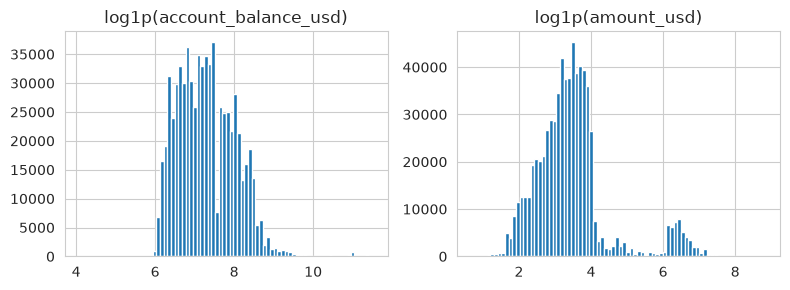

Skewed candidates: ['account_balance_usd', 'amount_usd']


In [6]:
skewed = summary[summary["skew"] > 2].index.tolist()[:4]
fig, axes = plt.subplots(1, len(skewed), figsize=(4 * len(skewed), 3))
if len(skewed) == 1: axes = [axes]
for ax, col in zip(axes, skewed):
    np.log1p(train[col].clip(lower=0)).hist(bins=80, ax=ax)
    ax.set(title=f"log1p({col})")
plt.tight_layout(); plt.show()
print("Skewed candidates:", skewed)

### Does fraud rate vary by hour / day?

Hour   — min 1.44%   max 1.83%
Day    — min 1.58%   max 1.78%


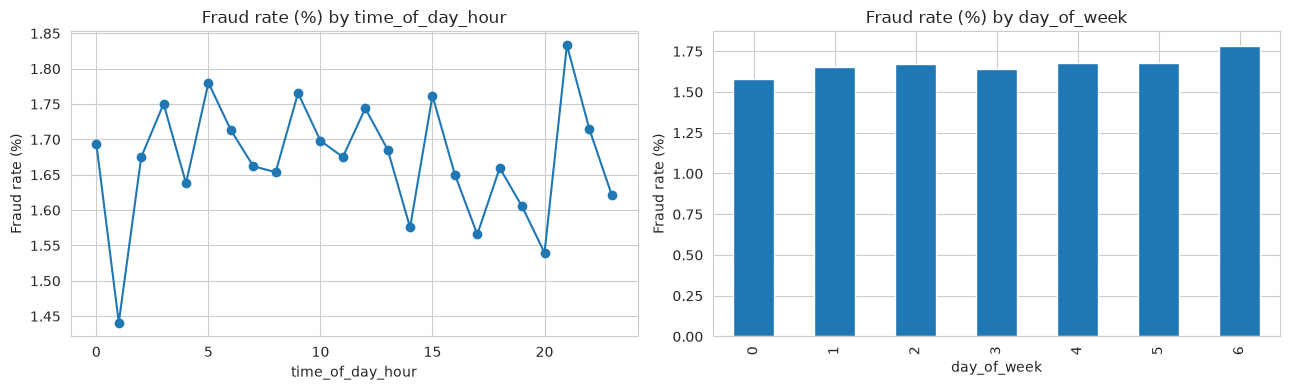

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

if "time_of_day_hour" in train.columns:
    hr = train.groupby("time_of_day_hour")[TARGET].mean() * 100
    hr.plot(kind="line", marker="o", ax=axes[0],
            title="Fraud rate (%) by time_of_day_hour", ylabel="Fraud rate (%)")
    print(f"Hour   — min {hr.min():.2f}%   max {hr.max():.2f}%")

if "day_of_week" in train.columns:
    dw = train.groupby("day_of_week")[TARGET].mean() * 100
    dw.plot(kind="bar", ax=axes[1],
            title="Fraud rate (%) by day_of_week", ylabel="Fraud rate (%)")
    print(f"Day    — min {dw.min():.2f}%   max {dw.max():.2f}%")

plt.tight_layout(); plt.show()

### Does any feature separate the classes?

In [8]:
feat_for_diff = [c for c in numeric_cols if c not in (ID_COL,)]
means = train.groupby(TARGET)[feat_for_diff].mean().T
means.columns = ["legit_mean", "fraud_mean"]
means["abs_diff"]    = (means["fraud_mean"] - means["legit_mean"]).abs()
means["pct_diff"]    = (means["abs_diff"] / (means["legit_mean"].abs() + 1e-9) * 100)
print(means.sort_values("pct_diff", ascending=False).round(3).to_string())

                       legit_mean  fraud_mean  abs_diff  pct_diff
velocity_score             18.786      27.404     8.618    45.877
amount_usd                 79.373     110.505    31.131    39.221
merchant_risk_score        35.011      47.368    12.357    35.295
customer_age               51.300      59.129     7.829    15.262
hours_since_last_txn        6.651       5.645     1.006    15.124
account_balance_usd      2064.521    2093.092    28.571     1.384
distance_from_home_km      13.585      13.750     0.166     1.219
card_age_months            46.862      46.892     0.030     0.063
time_of_day_hour           11.762      11.759     0.003     0.023


### Categorical fraud rates

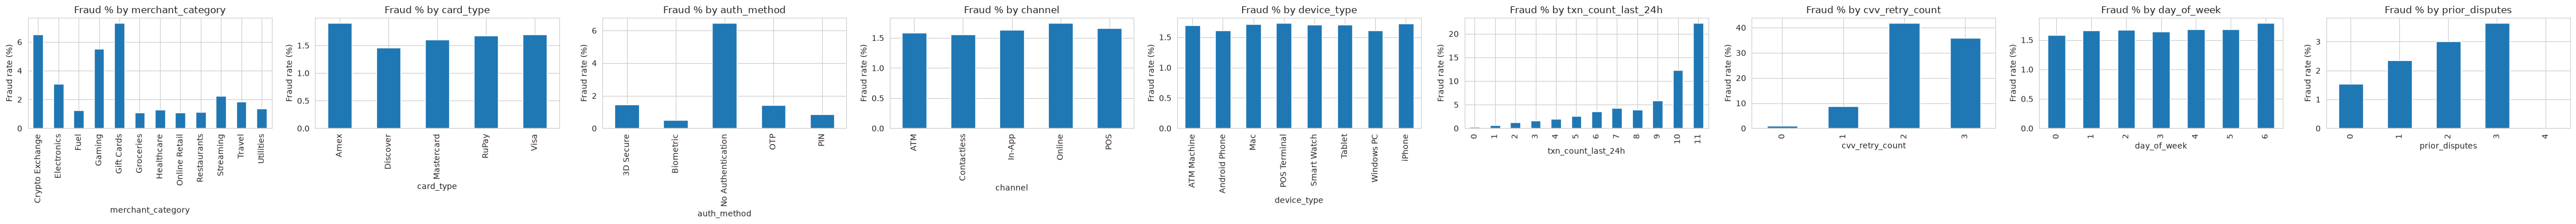


merchant_category — value counts:
merchant_category
Online Retail    155097
Groceries        142578
Restaurants      101360
Fuel              59880
Electronics       48693
Streaming         47196
Utilities         42027
Healthcare        35889
Travel            28715
Gaming            23784

card_type — value counts:
card_type
Visa          345001
Mastercard    254857
Amex           45797
RuPay          37070
Discover       17235

auth_method — value counts:
auth_method
3D Secure            210036
OTP                  175178
PIN                  154020
Biometric             93666
No Authentication     67060

channel — value counts:
channel
Online         273939
POS            206465
Contactless    105620
In-App          83716
ATM             30220

device_type — value counts:
device_type
Android Phone    237454
iPhone           164691
POS Terminal     113237
Windows PC        80934
Mac               33973
Tablet            27688
Smart Watch       21106
ATM Machine       20877

txn_cou

In [9]:
if categorical_cols:
    fig, axes = plt.subplots(1, len(categorical_cols),
                             figsize=(5 * len(categorical_cols), 4))
    if len(categorical_cols) == 1: axes = [axes]
    for ax, col in zip(axes, categorical_cols):
        rates = train.groupby(col)[TARGET].agg(["mean", "count"])
        rates["mean"] *= 100
        rates["mean"].plot(kind="bar", ax=ax,
                           title=f"Fraud % by {col}")
        ax.set_ylabel("Fraud rate (%)")
    plt.tight_layout(); plt.show()

    for col in categorical_cols:
        print(f"\n{col} — value counts:")
        print(train[col].value_counts().head(10).to_string())

In [10]:
takeaways = f"""
## EDA Takeaways — S6E11 Fraud

- Rows: {len(train):,} train / {len(test):,} test
- Target: `{TARGET}`, fraud rate = {pct[1]:.3f}%  (ratio 1:{counts[0]/counts[1]:.1f})
- Baseline accuracy (predict all-0) = {pct[0]:.3f}%  → **accuracy is banned**
- Metric: **PR-AUC** + recall@fixed-FPR + business cost
- Missing values total: {train.isnull().sum().sum():,}
- Numeric features  : {len(numeric_cols)}
- Categorical features: {len(categorical_cols)} → {categorical_cols}
- Skewed features   : {skewed if 'skewed' in globals() else 'see cell 5'}
- Time signal       : time_of_day_hour / day_of_week already engineered
- Preprocessing plan:
  - [ ] log1p on heavily skewed amount-like columns
  - [ ] OneHot for low-cardinality categoricals; Ordinal for high-card
  - [ ] class_weight='balanced' for baseline LogReg
  - [ ] StratifiedKFold(5) on is_fraud
  - [ ] LightGBM as primary model (handles NaN, categoricals natively)
"""
print(takeaways)


## EDA Takeaways — S6E11 Fraud

- Rows: 699,960 train / 299,984 test
- Target: `is_fraud`, fraud rate = 1.670%  (ratio 1:58.9)
- Baseline accuracy (predict all-0) = 98.330%  → **accuracy is banned**
- Metric: **PR-AUC** + recall@fixed-FPR + business cost
- Missing values total: 0
- Numeric features  : 9
- Categorical features: 9 → ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'txn_count_last_24h', 'cvv_retry_count', 'day_of_week', 'prior_disputes']
- Skewed features   : ['account_balance_usd', 'amount_usd']
- Time signal       : time_of_day_hour / day_of_week already engineered
- Preprocessing plan:
  - [ ] log1p on heavily skewed amount-like columns
  - [ ] OneHot for low-cardinality categoricals; Ordinal for high-card
  - [ ] class_weight='balanced' for baseline LogReg
  - [ ] StratifiedKFold(5) on is_fraud
  - [ ] LightGBM as primary model (handles NaN, categoricals natively)

